## 1 : Import the libraries

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage


## 2 : Loading  images

Image 1 shape: (2799, 2799, 3)
Image 2 shape: (2799, 2799, 3)


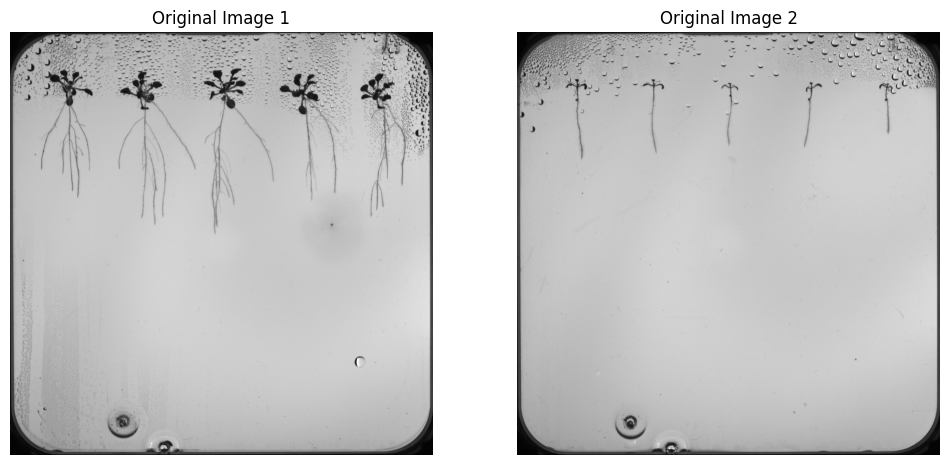

In [2]:
# Load both task 3 images
img1 = cv2.imread(r"task3_image_1.png")
img2 = cv2.imread(r"task3_image_2.png")

# Check that they loaded correctly
print("Image 1 shape:", img1.shape)
print("Image 2 shape:", img2.shape)

# Convert BGR → RGB for plotting
img1_rgb = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
img2_rgb = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)

# Show them side by side
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img1_rgb)
plt.title("Original Image 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img2_rgb)
plt.title("Original Image 2")
plt.axis("off")

plt.show()


## 3 : Grayscale + Blur for both images 

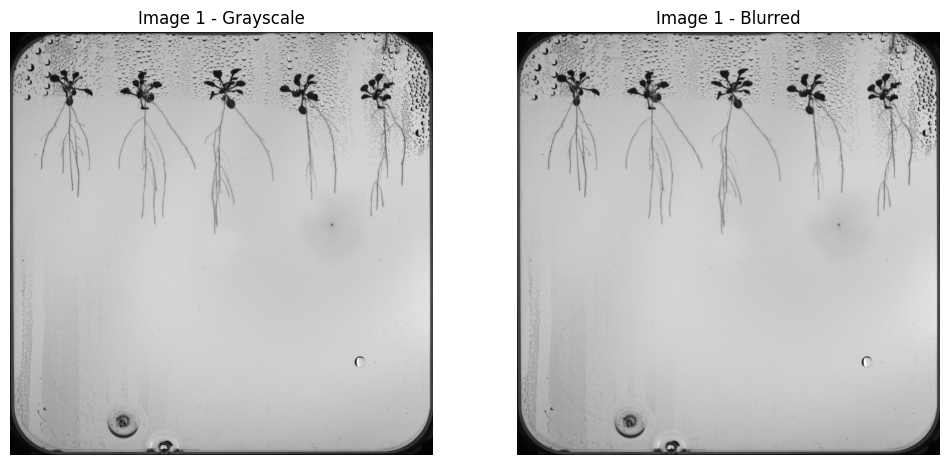

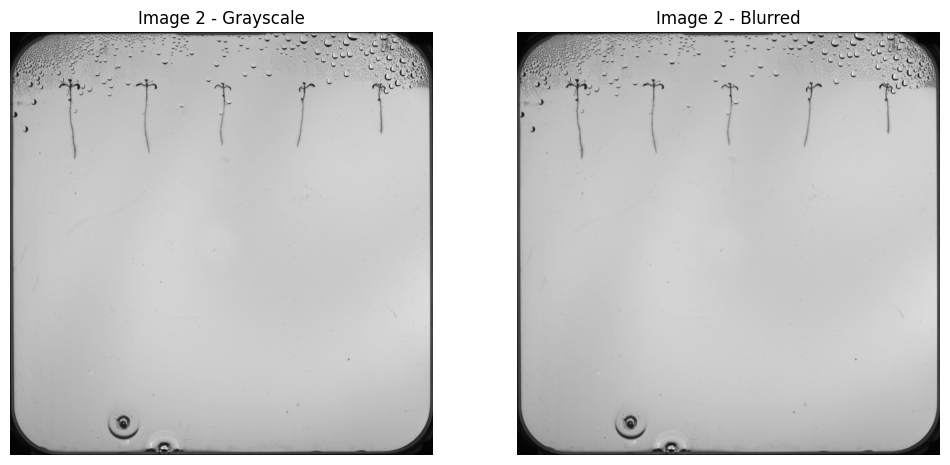

In [3]:


''' Grayscale + Blur
converted the image to grayscale to make it simpler because plants are dark and the background is bright.
Then Notram added a Gaussian Blur to smooth the image and remove small noise, so the next step (thresholding) works better.'''

# Convert both images to grayscale
img1_gray = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
img2_gray = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

#  Gaussian Blur (helps thresholding)
img1_blur = cv2.GaussianBlur(img1_gray, (5, 5), 0)
img2_blur = cv2.GaussianBlur(img2_gray, (5, 5), 0)

# plot grayscale + blurred images for image 1
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img1_gray, cmap='gray')
plt.title("Image 1 - Grayscale")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img1_blur, cmap='gray')
plt.title("Image 1 - Blurred")
plt.axis('off')

plt.show()
# plot grayscale + blurred images for image 2
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img2_gray, cmap='gray')
plt.title("Image 2 - Grayscale")
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(img2_blur, cmap='gray')
plt.title("Image 2 - Blurred")
plt.axis('off')
plt.show()

## 5 : Thresholding (turn plants white, background black)

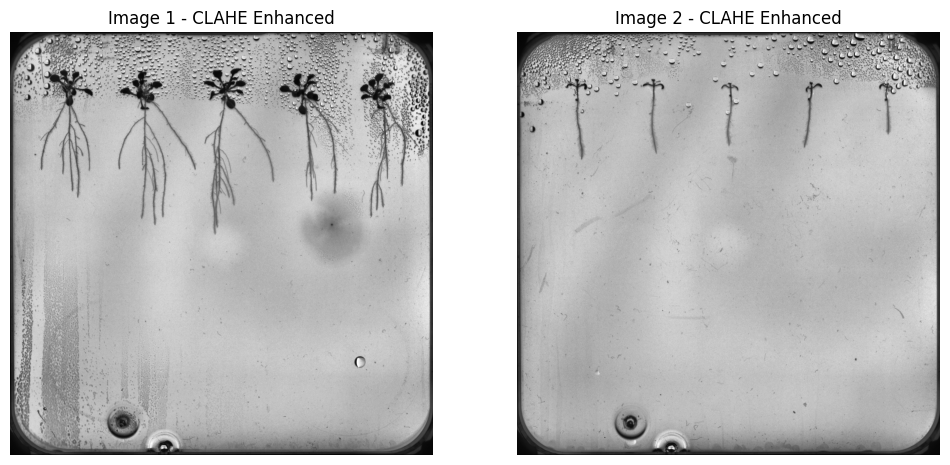

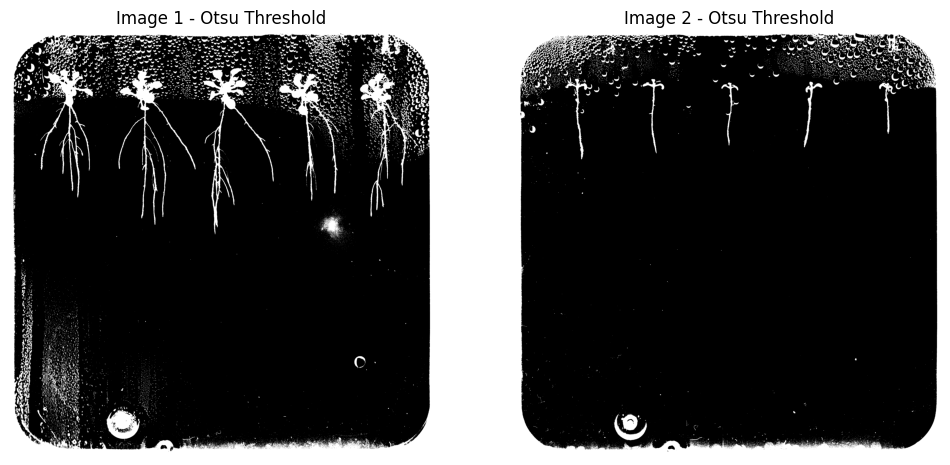

In [4]:
## CLAHE

'''used CLAHE to increase the contrast in the image. This makes the plants (roots + shoots) darker and the background
brighter. With higher contrast, the threshold step becomes much
more accurate and easier for the computer. '''


clahe = cv2.createCLAHE(clipLimit=4, tileGridSize=(8, 8))

# Apply CLAHE
img1_clahe = clahe.apply(img1_gray)
img2_clahe = clahe.apply(img2_gray)

# Show CLAHE results
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img1_clahe, cmap='gray')
plt.title("Image 1 - CLAHE Enhanced")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img2_clahe, cmap='gray')
plt.title("Image 2 - CLAHE Enhanced")
plt.axis('off')

plt.show()

# Thresholding (Otsu)
'''
used Otsu's thresholding to turn the plants into white shapes and the background into black. This creates a clean binary mask that
is easy for the computer to use when finding each plant.
Otsu chooses the best threshold automatically.'''

_, img1_otsu = cv2.threshold(
    img1_clahe, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

_, img2_otsu = cv2.threshold(
    img2_clahe, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Show Threshold results
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(img1_otsu, cmap='gray')
plt.title("Image 1 - Otsu Threshold")
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(img2_otsu, cmap='gray')
plt.title("Image 2 - Otsu Threshold")
plt.axis('off')
plt.show()



## 6 : Removing Small Objects (Noise Filtering)

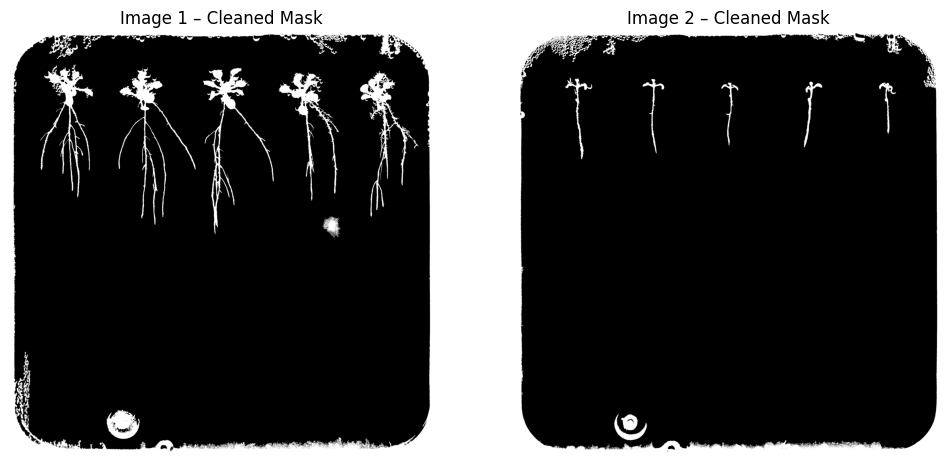

In [ ]:
def remove_small_objects(binary_image, min_size=2500):
    """
    Removes all white objects smaller than min_size.
    This deletes water droplets and random noise.
    Plants remain because they are large.
    """
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(binary_image)

    cleaned = np.zeros_like(binary_image)

    for i in range(1, num_labels):  # skip background (0)
        area = stats[i, cv2.CC_STAT_AREA]
        if area >= min_size:
            cleaned[labels == i] = 255

    return cleaned

# Apply cleaning to both images
img1_clean = remove_small_objects(img1_otsu, min_size=2500)
img2_clean = remove_small_objects(img2_otsu, min_size=2500)

# Show cleaned masks
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img1_clean, cmap='gray')
plt.title("Image 1 – Cleaned Mask")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img2_clean, cmap='gray')
plt.title("Image 2 – Cleaned Mask")
plt.axis("off")

plt.show()


## 7 : Final Cleaning of the Binary Mask

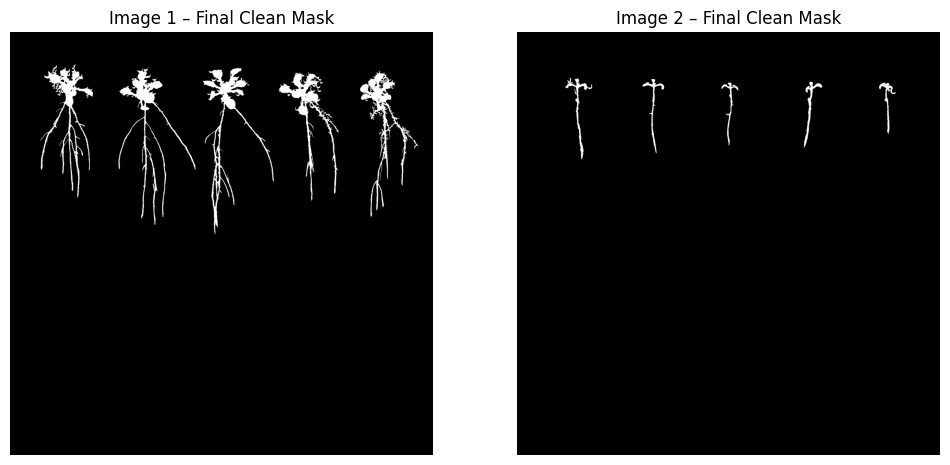

In [ ]:

 """
    Removes unwanted objects from the binary image by checking their size
    and position.

    - Removes objects touching the very top (usually reflections).
    - Removes long thin lines near the top (dish edge / glare).
    - Removes objects in the lower half of the image (bottom bubble area).
    - Removes objects smaller than 'min_area' (noise or tiny blobs).

    The goal is to keep only the plant shapes.
    """
def clean_final(binary_img, min_area=10000):
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(binary_img)
    cleaned = np.zeros_like(binary_img)

    H, W = binary_img.shape

    for i in range(1, num_labels):
        x, y, w, h, area = stats[i]

        if y == 0:
            continue

        if h < 20 and w > 300:
            continue

        if y > H * 0.50:
            continue

        if area < min_area:
            continue

        cleaned[labels == i] = 255

    return cleaned
# Image 1 – large plants
img1_cleanfinal = clean_final(img1_clean, min_area=10000)

# Image 2 – tiny plants
img2_cleanfinal = clean_final(img2_clean, min_area=3000)
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(img1_cleanfinal, cmap='gray')
plt.title("Image 1 – Final Clean Mask")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img2_cleanfinal, cmap='gray')
plt.title("Image 2 – Final Clean Mask")
plt.axis("off")
plt.show()


## 8 : Labeling and Coloring Each Plant

Image 1 plants detected: 5
Image 2 plants detected: 5


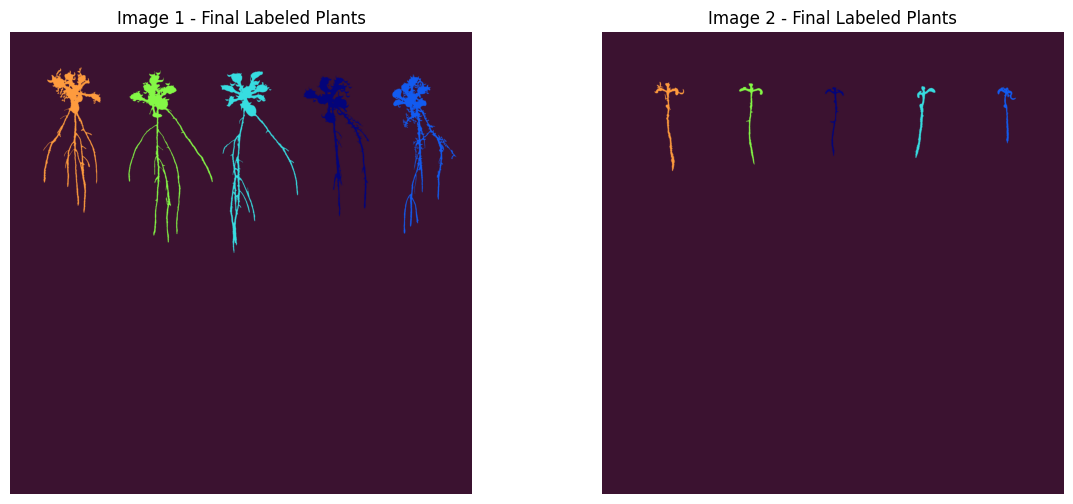

In [ ]:
def label_plants(binary_image):
    """
    Labels each plant with a different color.
    Returns a color visualization.
    """
    num_labels, labels = cv2.connectedComponents(binary_image)

    # Convert labels to color image for display
    label_viz = cv2.applyColorMap(
        ((labels / labels.max()) * 255).astype(np.uint8), 
        cv2.COLORMAP_TURBO
    )

    return label_viz, labels, num_labels


# Apply to  cleaned masks 
viz1, labels1, n1 = label_plants(img1_cleanfinal)
viz2, labels2, n2 = label_plants(img2_cleanfinal)

print("Image 1 plants detected:", n1 - 1)  
print("Image 2 plants detected:", n2 - 1)


plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.imshow(viz1)
plt.title("Image 1 - Final Labeled Plants")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(viz2)
plt.title("Image 2 - Final Labeled Plants")
plt.axis("off")
plt.show()
